# EDA

<h3>EDA Cell 0 - Load Dataset Berlabel & Setup</h3>
<p>
Kami memulai EDA lanjutan dengan membaca dataset hasil proses labeling (misalnya <code>sparc_labeled.csv</code>).
Dataset ini sudah memiliki kolom target <code>label_repeat_next</code> serta beberapa kolom helper untuk validasi waktu.
</p>
<p>
Pada cell ini kami juga menyiapkan konfigurasi tampilan dan import library agar cell berikutnya fokus ke analisis (tidak mengulang import).
</p>

In [60]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

# TODO: sesuaikan path/nama file
DATA_PATH = "sparc_labeled.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
display(df.head(3))
display(df.dtypes)

Shape: (319978, 30)


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer
0,CUST-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03,1,2e,27.0,21000000.0,8600000.0,MC,Balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02
1,CUST-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27,1,2b,28.0,87800000.0,20600000.0,MC,Balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02
2,CUST-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-04-01,1,4b,37.0,0.0,0.0,MH,Balikpapan,SCOOTY SERIES,kurang 1 juta,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,2019-01-02,6471-6400,1.0,2020-08-25


customer id                object
kelurahan                  object
kecamatan                  object
kode pos                   object
cash/credit               float64
kode dealer               float64
finance company            object
tenor                      object
gender                     object
tgl lahir                  object
agama                      object
pekerjaan                  object
umur                      float64
dp aktual                 float64
cicilan                   float64
warna                      object
dealer                     object
type series                object
range dp                   object
wilayah                    object
9 segment                  object
kode motor                 object
otr                       float64
tahun rakit                object
dlr group                  object
tgl cetak                  object
tgl mohon                  object
kode kota-provinsi         object
label_repeat_next         float64
max_tgl_mohon_

<h3>EDA Cell 1 - Sanity Check Label + Visualisasi Distribusi</h3>
<p>
Kami memeriksa kualitas label dengan melihat distribusi nilai <code>label_repeat_next</code>:
berapa banyak data berlabel <b>0</b>, <b>1</b>, dan yang masih kosong (<i>NaN</i>).
Selain tabel ringkas, kami juga menampilkan plot bar agar ketimpangan kelas (imbalance) terlihat jelas.
</p>
<p>
Langkah ini penting karena dataset repeat-next umumnya sangat imbalanced (label 1 jauh lebih sedikit),
sehingga metrik seperti ROC AUC dan threshold tuning menjadi relevan pada tahap modeling.
</p>

Distribusi label (termasuk NaN):


label_repeat_next
0.0    194516
NaN     97664
1.0     27798
Name: count, dtype: int64

Jumlah data berlabel: 222314
Repeat rate (label=1): 0.1250


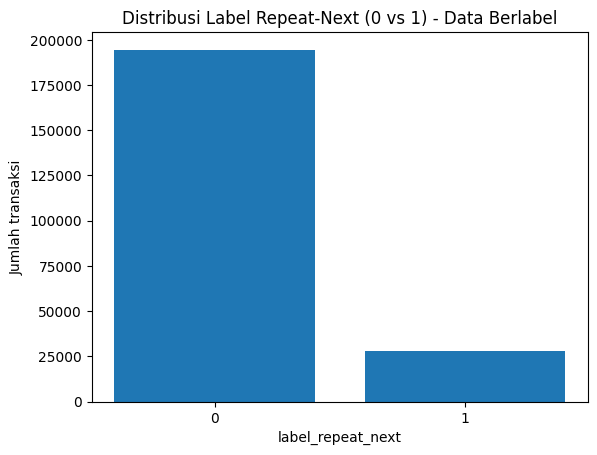

In [61]:
label_col = "label_repeat_next"

vc_all = df[label_col].value_counts(dropna=False)
print("Distribusi label (termasuk NaN):")
display(vc_all)

df_labeled = df[df[label_col].notna()].copy()
df_labeled[label_col] = df_labeled[label_col].astype(int)

vc = df_labeled[label_col].value_counts().sort_index()
repeat_rate = df_labeled[label_col].mean()

print("Jumlah data berlabel:", len(df_labeled))
print(f"Repeat rate (label=1): {repeat_rate:.4f}")

plt.figure()
plt.bar(vc.index.astype(str), vc.values)
plt.title("Distribusi Label Repeat-Next (0 vs 1) - Data Berlabel")
plt.xlabel("label_repeat_next")
plt.ylabel("Jumlah transaksi")
plt.show()
plt.close("all")

<h3>EDA Cell 2 - Ringkasan Dataset & Cakupan Waktu</h3>
<p>
Pada cell ini kami membuat ringkasan cepat terkait struktur dataset:
jumlah kolom, beberapa contoh nilai, serta perkiraan cakupan waktu transaksi.
Tujuannya untuk memastikan data masuk akal sebelum masuk ke analisis kategori dan numerik.
</p>

In [62]:
print("Shape (all):", df.shape)
print("Shape (labeled):", df_labeled.shape)

candidate_date_cols = [
    c for c in df.columns
    if any(k in c.lower() for k in ["tgl", "date", "tanggal"])
]
print("Candidate date columns:", candidate_date_cols)

if "tgl mohon" in df.columns:
    tmp_dt = pd.to_datetime(df["tgl mohon"], errors="coerce")
    print("Cakupan tgl mohon:", tmp_dt.min(), "->", tmp_dt.max())

display(df_labeled.sample(5, random_state=42))

Shape (all): (319978, 30)
Shape (labeled): (222314, 30)
Candidate date columns: ['tgl lahir', 'tgl cetak', 'tgl mohon', 'max_tgl_mohon_customer']
Cakupan tgl mohon: 2019-01-02 00:00:00 -> 2025-12-31 00:00:00


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer
152869,CUST-14365,BATU AMPAR,BALIKPAPAN UTARA,76136,2.0,126157.0,1,2,1,2001-01-18,1,2c,220.0,47000000.0,13500000.0,BK,Balikpapan,GENEX SERIES,3 juta up,6471,AT LOW,LB,212900000.0,2023,NaN,NaN,2023-01-18,6471-6400,0,2023-01-18
268260,CUST-183236,GUNUNG SARI ULU,BALIKPAPAN TENGAH,76122,2.0,733.0,1,2,1,1998-08-10,1,2e,27.0,3600000.0,2000000.0,SV,Balikpapan,PXE,3 juta up,6471,AT HIGH,LT,35700000.0,2024,NaN,NaN,2024-12-31,6471-6400,0,2024-12-31
131703,CUST-207410,KLANDASAN ILIR,BALIKPAPAN KOTA,76113,2.0,13115.0,1,2,1,1985-12-29,1,4f,37.0,40000000.0,13500000.0,BK,Balikpapan,SCOOTY SERIES,3 jt up,6471,AT MID,LR,23710000.0,2022,NaN,NaN,2022-08-10,6471-6400,0,2022-08-10
26629,CUST-246473,Juata Permai,Tarakan Utara,77116,1.0,16609.0,N,N,2,2001-09-11,1,5,18.0,0.0,0.0,BL,Tarakan,VAREX 150,krg 1 juta,6571,AT HIGH,HY,25350000.0,2019.0,NaN,NaN,2019-08-19,6571-6500,0,2019-08-19
300813,CUST-68134,DUMARING,TALISAYAN,77372,1.0,2834.0,N,N,1,1988-12-22,3,2e,37.0,0.0,0.0,BR,Berau,RYVO SERIES,krg 1 jt,6405.0,CUB LOW,GD,15599000.0,2025,NaN,NaN,2025-08-13,6405-6400,0,2025-08-13


<h3>EDA Cell 3 - Missing Value & Kualitas Data</h3>
<p>
Kami memeriksa missing values pada data berlabel untuk mengidentifikasi fitur yang
membutuhkan imputasi, pembersihan, atau perlu di-drop pada modeling.
Output disajikan sebagai tabel persentase missing agar mudah diprioritaskan.
</p>

In [63]:
missing = (df_labeled.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
print("Kolom yang memiliki missing value (%):")
display(missing.to_frame("missing_pct"))

Kolom yang memiliki missing value (%):


,missing_pct
tgl cetak,100.000000
dlr group,80.945420
tahun rakit,4.451362
dp aktual,0.191171
cicilan,0.172279
finance company,0.031937
kode motor,0.017543
tenor,0.005848
otr,0.001799
kelurahan,0.000450


<h3>EDA Cell 4 - Normalisasi Kategori (Strip + Normalisasi ID-like)</h3>
<p>
Sebelum melakukan analisis repeat rate per kategori, kami menormalkan nilai pada fitur kategorikal:
menghapus spasi berlebih (<i>strip</i>) dan menyederhanakan kolom yang bersifat ID-like
(misal: kode dealer, kode cabang, kode mitra) agar lebih konsisten.
</p>
<p>
Tujuannya adalah mengurangi fragmentasi kategori akibat variasi format penulisan
(seperti spasi, huruf besar/kecil, atau tanda baca) yang dapat mengganggu interpretasi statistik.
</p>

In [ ]:
def normalize_id_like(series: pd.Series) -> pd.Series:
    s = series.astype("string")
    s = s.str.strip()
    s = s.str.lower()
    s = s.str.replace(r"\s+", " ", regex=True)
    s = s.str.replace(r"[^\w\s\-\/]", "", regex=True)
    return s

cat_fix_cols = [c for c in df_labeled.columns if df_labeled[c].dtype == "object"]
cat_fix_cols = [c for c in cat_fix_cols if c not in [label_col]]

id_like_cols = [c for c in cat_fix_cols if any(k in c.lower() for k in ["id", "kode", "code", "no", "dealer", "branch", "cabang"])]
id_like_cols = [c for c in id_like_cols if "tenor" not in c.lower()]
# 1) strip dasar untuk semua kategori
for c in cat_fix_cols:
    df_labeled[c] = df_labeled[c].astype("string").str.strip()

# 2) normalisasi lebih kuat untuk ID-like
for c in id_like_cols:
    df_labeled[c] = normalize_id_like(df_labeled[c])

print("Jumlah kolom kategori dibersihkan:", len(cat_fix_cols))
print("Kolom yang dianggap ID-like:", id_like_cols[:20], "..." if len(id_like_cols) > 20 else "")

for c in id_like_cols[:5]:
    print(f"\nTop kategori untuk: {c}")
    display(df_labeled[c].value_counts(dropna=False).head(10))

Jumlah kolom kategori dibersihkan: 23
Kolom yang dianggap ID-like: ['customer id', 'kode pos', 'dealer', 'kode motor', 'kode kota-provinsi'] 

Top kategori untuk: customer id


customer id
cust-266618    247
cust-266623    242
cust-266564    211
cust-05206     168
cust-05116     149
cust-05078     123
cust-265993     99
cust-266005     92
cust-266539     84
cust-03220      77
Name: count, dtype: Int64


Top kategori untuk: kode pos


kode pos
76115    11269
76251     9615
77315     9273
76114     8474
76116     8184
76125     8000
77111     6388
77212     6288
77482     6146
77371     5712
Name: count, dtype: Int64


Top kategori untuk: dealer


dealer
balikpapan    89272
berau         34830
paser         32477
tarakan       23965
ppu           19240
bulungan      14344
nunukan        8186
Name: count, dtype: Int64


Top kategori untuk: kode motor


kode motor
hr    19245
lp    15274
lr    15157
lm    12215
ll    10968
lx    10558
lj     7031
mo     6845
lb     6771
eu     6578
Name: count, dtype: Int64


Top kategori untuk: kode kota-provinsi


kode kota-provinsi
6471-6400    80610
6405-6400    34510
6401-6400    33290
6571-6500    21640
6409-6400    21293
6502-6500    13963
6504-6500     9114
6403-6400     3101
6503-6500     1292
6472-6400      987
Name: count, dtype: Int64

<h3>EDA Cell 5 - Repeat Rate per Kategori (Fokus Kolom Utama)</h3>
<p>
Kami menghitung repeat rate (<code>mean(label_repeat_next)</code>) untuk beberapa fitur kategori utama.
Agar insight tidak menjadi sekadar dump tabel, kami membatasi analisis pada kolom-kolom yang paling relevan
dan menerapkan filter <code>min_n</code> sehingga kategori yang terlalu jarang tidak mendistorsi interpretasi.
</p>
<p>
Output diambil <b>Top-N</b> kategori dengan jumlah data memadai dan repeat rate yang informatif.
Kolom kategori lain dapat dianalisis sebagai lampiran bila diperlukan.
</p>

In [ ]:
def repeat_rate_by(col: str, min_n: int = 200) -> pd.DataFrame:
    tmp = df_labeled.groupby(col)[label_col].agg(["count", "mean"]).reset_index()
    tmp = tmp.rename(columns={"count": "n", "mean": "repeat_rate"})
    tmp = tmp[tmp["n"] >= min_n].sort_values(["repeat_rate", "n"], ascending=[False, False])
    tmp["repeat_rate_pct"] = (tmp["repeat_rate"] * 100).round(2)
    return tmp

candidate_focus = [
    "9 segment", "dealer", "finance company", "wilayah", "tenor"
]
focus_cols = [c for c in candidate_focus if c in df_labeled.columns]

print("Kolom kategori fokus yang ditemukan:", focus_cols)

for col in focus_cols:
    print("\n=== Repeat rate by:", col, "===")
    tab = repeat_rate_by(col, min_n=200)
    display(tab.head(10))

Kolom kategori fokus yang ditemukan: ['9 segment', 'dealer', 'finance company', 'wilayah', 'tenor']

=== Repeat rate by: 9 segment ===


,9 segment,n,repeat_rate,repeat_rate_pct
8,SPORT LOW,6794,0.463939,46.39
4,CUB LOW,6395,0.260360,26.04
9,SPORT MID,9129,0.170884,17.09
3,CUB HIGH,1815,0.169146,16.91
5,CUB MID,4512,0.165559,16.56
1,AT LOW,79011,0.110314,11.03
2,AT MID,76160,0.103020,10.30
0,AT HIGH,38218,0.098383,9.84



=== Repeat rate by: dealer ===


,dealer,n,repeat_rate,repeat_rate_pct
0,balikpapan,89272,0.142150,14.21
1,berau,34830,0.134941,13.49
6,tarakan,23965,0.118381,11.84
5,ppu,19240,0.105665,10.57
4,paser,32477,0.101456,10.15
2,bulungan,14344,0.100600,10.06
3,nunukan,8186,0.097728,9.77



=== Repeat rate by: finance company ===


,finance company,n,repeat_rate,repeat_rate_pct
1,11,4988,0.156375,15.64
5,2,10118,0.145977,14.60
3,13,1125,0.131556,13.16
8,3,2458,0.130594,13.06
15,N,97309,0.128272,12.83
0,1,92857,0.122619,12.26
14,9,1288,0.118012,11.80
11,4,6457,0.091683,9.17
9,36,734,0.081744,8.17
7,26,340,0.079412,7.94



=== Repeat rate by: wilayah ===


,wilayah,n,repeat_rate,repeat_rate_pct
194,6402,252,0.535714,53.57
212,6501,549,0.411658,41.17
198,6404,778,0.244216,24.42
200,6405,30154,0.151025,15.10
206,6471,72822,0.150271,15.03
202,6409,18770,0.139531,13.95
220,6571,19702,0.127094,12.71
214,6502,12119,0.122040,12.20
192,6401,29131,0.113178,11.32
218,6504,7756,0.110237,11.02



=== Repeat rate by: tenor ===


,tenor,n,repeat_rate,repeat_rate_pct
0,1,26664,0.161679,16.17
6,N,97341,0.128137,12.81
1,2,75523,0.118679,11.87
2,3,22647,0.088974,8.90


<h3>EDA Cell 6 - Insight Numerik (Distribusi & Perbandingan per Label)</h3>
<p>
Kami menganalisis fitur numerik dengan membandingkan statistik ringkas antara label <b>0</b> dan <b>1</b>,
serta memvisualisasikan distribusi melalui boxplot.
Sebelum analisis, fitur numerik yang tersimpan sebagai <i>object</i> akan dicoba dikonversi menjadi numeric.
</p>
<p>
Untuk menghindari duplikasi, variabel seperti <code>tenor</code> diperlakukan sebagai kategori pada Cell 5,
sehingga Cell ini fokus pada nilai numerik kontinu (misalnya: dp, cicilan, umur, otr, dll).
</p>

Kolom numerik yang dianalisis: ['umur', 'dp aktual', 'cicilan', 'range dp', 'otr']


,count_0,mean_0,median_0,std_0,count_1,mean_1,median_1,std_1
umur,194516.0,84.849938,38.0,125.096508,27798.0,78.243651,38.0,117.998363
dp aktual,194167.0,15847115.008163,2100000.0,49656367.338381,27722.0,21241569.63823,6000000.0,182697030.630292
cicilan,194204.0,8140135.455655,1435000.0,351217848.368729,27727.0,10086798.256321,2450000.0,183271439.601213
range dp,0.0,<NA>,<NA>,<NA>,0.0,<NA>,<NA>,<NA>
otr,194514.0,58660618.553009,23160000.0,84064870.515295,27796.0,51513680.961289,22070000.0,77417055.739312


<Figure size 640x480 with 0 Axes>

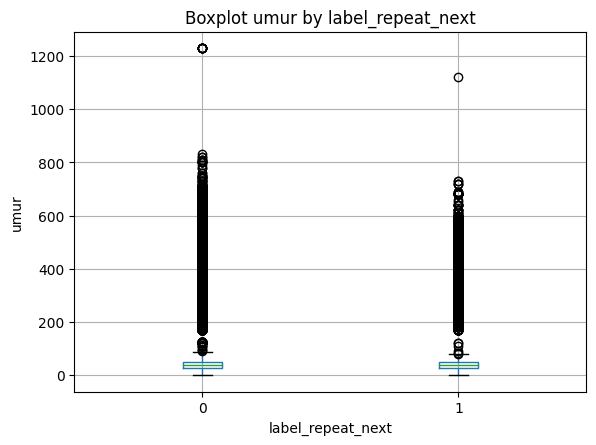

<Figure size 640x480 with 0 Axes>

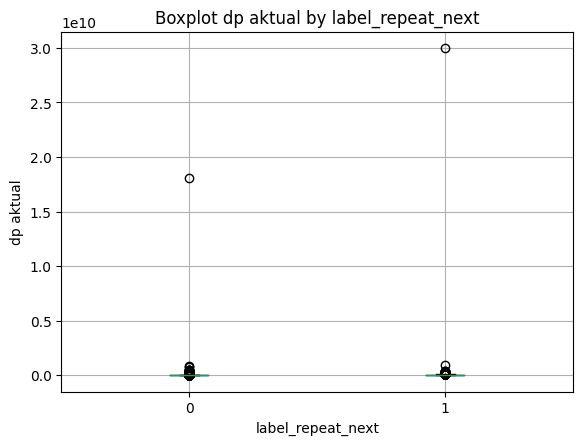

<Figure size 640x480 with 0 Axes>

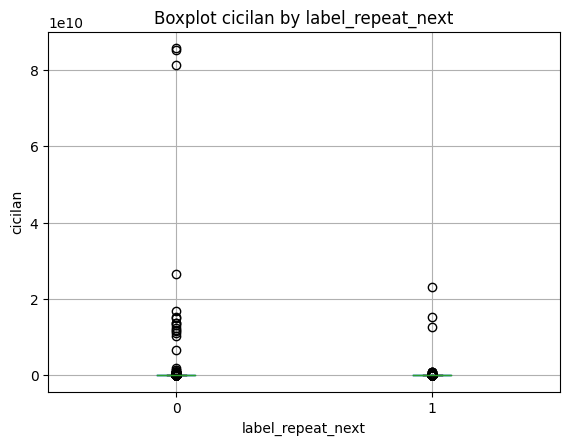

<Figure size 640x480 with 0 Axes>

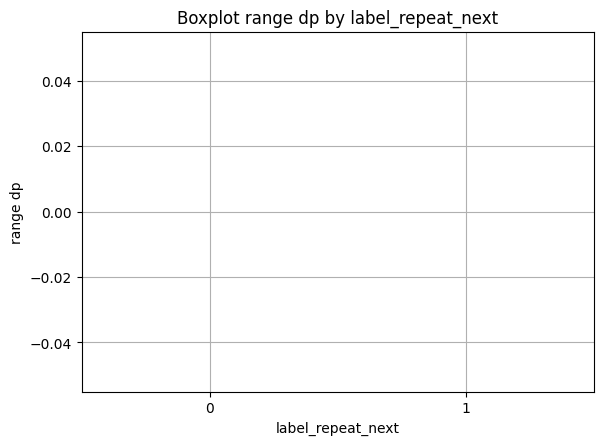

<Figure size 640x480 with 0 Axes>

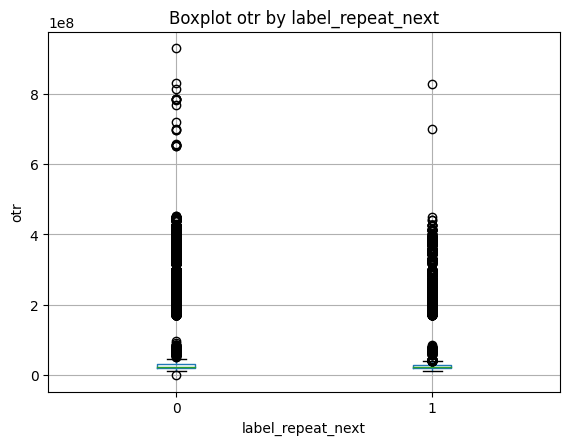

In [ ]:

numeric_candidates = [
    "dp", "cicilan", "otr", "umur", "harga", "down payment", "installment"
]


num_cols = [c for c in df_labeled.columns if any(k in c.lower() for k in ["dp", "cicil", "otr", "umur", "harga"])]
num_cols = [c for c in num_cols if "tenor" not in c.lower()]

for c in num_cols:
    df_labeled[c] = pd.to_numeric(df_labeled[c], errors="coerce")

print("Kolom numerik yang dianalisis:", num_cols)


if len(num_cols) > 0:
    stats_0 = df_labeled[df_labeled[label_col] == 0][num_cols].describe().T
    stats_1 = df_labeled[df_labeled[label_col] == 1][num_cols].describe().T

    stats = stats_0[["count", "mean", "50%", "std"]].rename(
        columns={"count": "count_0", "mean": "mean_0", "50%": "median_0", "std": "std_0"}
    ).join(
        stats_1[["count", "mean", "50%", "std"]].rename(
            columns={"count": "count_1", "mean": "mean_1", "50%": "median_1", "std": "std_1"}
        )
    )

    display(stats)

    show_cols = num_cols[:6]
    for c in show_cols:
        plt.figure()
        df_labeled.boxplot(column=c, by=label_col)
        plt.title(f"Boxplot {c} by label_repeat_next")
        plt.suptitle("")
        plt.xlabel("label_repeat_next")
        plt.ylabel(c)
        plt.show()
else:
    print("Tidak ada kolom numerik kandidat yang terdeteksi. Silakan sesuaikan list num_cols.")

<h3>EDA Cell 7 - Analisis Repeat per Customer</h3>
<p>
Kami mengecek apakah label repeat-next berkorelasi dengan perilaku pelanggan yang sering bertransaksi.
Dengan menghitung jumlah transaksi per customer dan menghubungkannya dengan repeat rate,
kita dapat melihat apakah pelanggan dengan aktivitas tinggi cenderung memiliki peluang repeat yang berbeda.
</p>

In [ ]:
candidate_customer_cols = [
    c for c in df_labeled.columns
    if any(k in c.lower() for k in ["customer", "cust", "pelanggan", "nik", "ktp"])
    and "max_" not in c.lower()
    and "tgl" not in c.lower()
]
print("Candidate customer id columns:", candidate_customer_cols)

customer_col = candidate_customer_cols[0] if len(candidate_customer_cols) > 0 else None

if customer_col is None:
    print("Kolom customer id tidak terdeteksi. Silakan set manual customer_col.")
else:
    cust_tab = df_labeled.groupby(customer_col)[label_col].agg(["count", "mean"]).reset_index()
    cust_tab = cust_tab.rename(columns={"count": "n_tx", "mean": "repeat_rate"})
    cust_tab["repeat_rate_pct"] = (cust_tab["repeat_rate"] * 100).round(2)

    display(cust_tab.sort_values("n_tx", ascending=False).head(20))

    cust_tab["tx_bin"] = pd.cut(cust_tab["n_tx"], bins=[1,2,3,5,10,20,50,100,10_000], right=True)
    bin_tab = cust_tab.groupby("tx_bin")["repeat_rate"].agg(["count", "mean"]).reset_index()
    bin_tab["repeat_rate_pct"] = (bin_tab["mean"] * 100).round(2)

    display(bin_tab)

Candidate customer id columns: ['customer id']


,customer id,n_tx,repeat_rate,repeat_rate_pct
138786,cust-266618,247,0.878543,87.85
138792,cust-266623,242,0.888430,88.84
138736,cust-266564,211,0.971564,97.16
3875,cust-05206,168,0.988095,98.81
3800,cust-05116,149,0.919463,91.95
3766,cust-05078,123,0.910569,91.06
138262,cust-265993,99,0.989899,98.99
138273,cust-266005,92,0.934783,93.48
138715,cust-266539,84,0.809524,80.95
2424,cust-03220,77,0.987013,98.70


,tx_bin,count,mean,repeat_rate_pct
0,"(1, 2]",16374,0.486717,48.67
1,"(2, 3]",2159,0.635943,63.59
2,"(3, 5]",742,0.670350,67.04
3,"(5, 10]",254,0.657463,65.75
4,"(10, 20]",107,0.697284,69.73
5,"(20, 50]",61,0.848310,84.83
6,"(50, 100]",10,0.914661,91.47
7,"(100, 10000]",6,0.926111,92.61


<h3>EDA Cell 7B - Appendix: Debug Customer Ekstrem</h3>
<p>
Sebagai lampiran, kami mengambil beberapa customer dengan transaksi terbanyak untuk memastikan tidak ada anomali ekstrim.
Kami hanya menampilkan contoh <b>10 baris</b> agar tidak membanjiri notebook.
Jika ditemukan pola aneh (misalnya transaksi banyak dalam satu hari), hal ini akan menjadi catatan untuk cleaning/modeling.
</p>

In [68]:
if customer_col is None:
    print("Skip: customer_col tidak tersedia.")
else:
    top_customers = cust_tab.sort_values("n_tx", ascending=False)[customer_col].head(3).tolist()
    print("Top customers (by n_tx):", top_customers)

    cols_show = [customer_col, label_col] + [c for c in df_labeled.columns if "date" in c.lower() or "tanggal" in c.lower()]
    cols_show = list(dict.fromkeys([c for c in cols_show if c in df_labeled.columns]))  # unique + exist

    for cid in top_customers:
        print(f"\n--- Sample rows for customer: {cid} ---")
        display(df_labeled[df_labeled[customer_col] == cid][cols_show].head(10))

Top customers (by n_tx): ['cust-266618', 'cust-266623', 'cust-266564']

--- Sample rows for customer: cust-266618 ---


,customer id,label_repeat_next
93748,cust-266618,1
93749,cust-266618,1
93750,cust-266618,1
93751,cust-266618,1
93752,cust-266618,1
93753,cust-266618,1
93754,cust-266618,1
93755,cust-266618,1
93756,cust-266618,1
93757,cust-266618,1



--- Sample rows for customer: cust-266623 ---


,customer id,label_repeat_next
92483,cust-266623,1
92484,cust-266623,1
92485,cust-266623,1
92486,cust-266623,1
92487,cust-266623,1
92488,cust-266623,1
92489,cust-266623,1
92490,cust-266623,1
92491,cust-266623,1
92492,cust-266623,1



--- Sample rows for customer: cust-266564 ---


,customer id,label_repeat_next
142412,cust-266564,1
142413,cust-266564,1
142414,cust-266564,1
142415,cust-266564,1
142416,cust-266564,1
142417,cust-266564,1
142418,cust-266564,1
142419,cust-266564,1
142420,cust-266564,1
142421,cust-266564,1
